# Rare earths and thorium

This is the most advanced notebook. It uses the two bundled databases that cover rare-earth elements (REE: the lanthanides and Y) and thorium.

**Read first.** Notebooks 01 (systems, `equilibrate`, complementarity) and 03 (loading PHREEQC databases). Background: [`docs/databases.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/databases.md) and [`docs/activity-models.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/activity-models.md).

**Terms.**
- *Molality* (m, mol/kgw): moles per kg of water. *Ionic strength* $I = \tfrac12\sum_i m_i z_i^2$.
- *Activity coefficient* γ: activity = γ × molality; far from 1 for highly charged ions such as Th⁴⁺.
- *Hydrolysis*: a metal ion binding OH⁻ as pH rises (Th⁴⁺ → ThOH³⁺ → … → Th(OH)₄(aq)).
- *Saturation index* SI = log(IAP/K). By complementarity a solid is either present (SI = 0) or absent (SI ≤ 0).
- $\log K$ is for dissolution, with the solid on the left.

| database | activity model | strengths | limits |
|----------|----------------|-----------|--------|
| [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat) (LLNL thermo.com V8 R6; Delany & Lundeen 1991) | LLNL B-dot (Helgeson 1969, [doi:10.2475/ajs.267.7.729](https://doi.org/10.2475/ajs.267.7.729)), A/B/ḃ tabulated to 300 °C | every lanthanide, Y, Th; hydroxides, carbonates, fluorides, hydrated phosphates; high temperature | I ≲ 1 m; many values are estimates; "relatively untested" per its header |
| [`sit.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/sit.dat) (ThermoChimie v12a; Giffaut et al. 2014, [doi:10.1016/j.apgeochem.2014.05.007](https://doi.org/10.1016/j.apgeochem.2014.05.007)) | SIT with 606 ε pairs | NEA-reviewed Th hydrolysis/carbonate data; ThO₂ at five crystallinities; brines | 25 °C for most data; of the lanthanides only Sm, Eu and Ho |

It covers:
1. ThO₂ solubility vs pH, in both databases and for several ThO₂ crystallinities;
2. rare-earth phosphates (La, Ce, Nd);
3. thorium in NaCl brines with SIT;
4. temperature dependence;
5. ore minerals that are **not** in either database (monazite, xenotime, bastnäsite, thorite), and how to add them.

Section 0 shows the evidence that the activity models and speciation reproduce PHREEQC for these databases.

In [1]:
import json, math, pathlib, re, time
import numpy as np
import matplotlib.pyplot as plt
from discopt.speciation import PhreeqcDatabase

ll = PhreeqcDatabase.load("llnl.dat")
si = PhreeqcDatabase.load("sit.dat")
for name, db in [("llnl.dat", ll), ("sit.dat", si)]:
    print(f"{name}: {len(db.species)} aqueous species, {len(db.phases)} phases, default model {db.default_activity()}")

def element_total(res, el):
    # Total dissolved molality of an element (mol/kgw): for each aqueous species,
    # atoms of `el` in its name (e.g. 4 in "Th4(OH)8+8") times its molality.
    # Solids are not in res.molality, so with a solid present this is its solubility.
    pat = re.compile(rf"{el}(?![a-z])(\d*)")
    return sum(sum(int(n or 1) for n in pat.findall(k)) * v for k, v in res.molality.items() if k != "H2O")

llnl.dat: 1327 aqueous species, 1215 phases, default model LLNL()
sit.dat: 1526 aqueous species, 924 phases, default model SIT()


## 0. Evidence: agreement with PHREEQC

**Goal.** Check that this package reproduces PHREEQC 3 (Parkhurst & Appelo 2013, [doi:10.3133/tm6A43](https://doi.org/10.3133/tm6A43)) on these two databases. You can skip this section on a first read.

[`tests/data/phreeqc_llnl_sit.json`](https://github.com/jkitchin/discopt-speciation/blob/main/tests/data/phreeqc_llnl_sit.json) holds PHREEQC results computed on the same files: Th and CO₂ in 0.1–3 m NaCl at pH 3, 25–150 °C, with Cl adjusted for charge balance. For each case the cell recomputes the speciation and prints the worst difference in log activity (species above 1e-20 m), the relative difference in ionic strength and the difference in log water activity. The file ships with the source repository; the cell skips itself if it is absent.

In [2]:
ref_path = pathlib.Path("..") / "tests" / "data" / "phreeqc_llnl_sit.json"
if not ref_path.exists():
    print(f"{ref_path} not found (it ships with the source repository); skipping the PHREEQC comparison.")
else:
    ref = json.loads(ref_path.read_text())
    dbs = {"llnl.dat": ll, "sit.dat": si}
    print(f"{'database':9s} {'T/°C':>5s} {'NaCl':>5s} {'species':>7s} {'max|Δ log a|':>13s} {'ΔI/I':>9s} {'Δ log a_w':>10s}")
    for c in ref["cases"]:
        s = dbs[c["database"]].system(["Na", "Cl", "Th", "C(4)"], T=273.15 + c["T_C"])
        r = s.equilibrate({"Na": c["Na"], "Cl": c["Na"], "Th": 1e-6, "C(4)": 1e-3}, pH=3, charge_balance="Cl-")
        cmp = [k for k in c["la"] if c["molality"][k] > 1e-20]   # species compared
        worst = max(abs(r.log10_activity[k] - c["la"][k]) for k in cmp)
        print(f"{c['database']:9s} {c['T_C']:5.0f} {c['Na']:5.1f} {len(cmp):7d} {worst:13.1e} "
              f"{r.ionic_strength / c['mu'] - 1:9.1e} {r.log10_activity['H2O'] - c['la_H2O']:10.1e}  converged={r.converged}")

database   T/°C  NaCl species  max|Δ log a|      ΔI/I  Δ log a_w
llnl.dat     25   0.1      22       2.8e-05  -1.8e-05    2.7e-08  converged=True


llnl.dat     60   1.0      23       4.9e-05  -1.7e-05    2.6e-07  converged=True
llnl.dat    150   1.0      24       1.3e-04  -1.6e-05    2.4e-07  converged=True


sit.dat      25   0.1      19       6.0e-05  -1.8e-05    2.6e-08  converged=True
sit.dat      25   3.0      19       1.3e-04  -1.8e-05    9.2e-07  converged=True


sit.dat      60   1.0      20       1.8e-04  -1.8e-05    2.5e-07  converged=True


**Result.** Log activities agree within about 2e-4, and ionic strength within 2e-5 relative. In [`sit.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/sit.dat) the largest differences are for polynuclear Th species such as Th₂(OH)₃⁵⁺ and Th₄(OH)₈⁸⁺, whose $\log\gamma$ scales with $z^2$ (25–64); in [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat) they are for Th chloride and hydroxide complexes. The same checks run as `tests/test_phreeqc.py::test_llnl_sit_match_phreeqc`.

## 1. ThO₂ solubility vs pH

**Data.** Both databases have crystalline ThO₂: `Thorianite` in [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat) ($\log K = 1.86$) and `ThO2(cr)` in [`sit.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/sit.dat) ($\log K = 1.77$), for ThO₂ + 4H⁺ = Th⁴⁺ + 2H₂O. The two independent compilations agree to 0.1 log units.

**Crystallinity.** A solid can form as well-ordered crystals or as a disordered, hydrated, fine-grained material; the less ordered forms are more soluble. [`sit.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/sit.dat) has such forms with much larger $\log K$: `ThO2(mcr)` (microcrystalline) 3.0, `ThO2(aged)` 8.5, `ThO2(fresh)` 9.3 and `ThO2(coll)` (colloidal) 11.1. Measured thorium solubility near room temperature is controlled by the hydrous, poorly crystalline solid, not by ThO₂(cr).

**Metastable equilibrium.** A *metastable* phase is not the most stable one but persists because conversion is slow. With all forms as candidates, complementarity keeps only ThO₂(cr). To compute the solubility of a metastable form, pass the more stable forms in `suppress=`.

**What the code does.** `th_curve` equilibrates 1e-2 mol/kgw of solid in 0.1 m NaCl at each pH and records dissolved Th and the phases present, for three cases: [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat) Thorianite, [`sit.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/sit.dat) with all four forms, and [`sit.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/sit.dat) ThO₂(fresh) with the others suppressed.

solve times: 2.5 s, 5.5 s, 4.8 s for 15 points each
phases present with all sit.dat forms as candidates: ['ThO2(cr)']


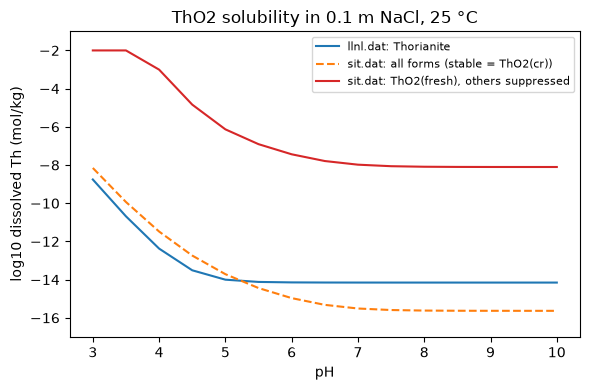

In [3]:
pHs = np.arange(3.0, 10.01, 0.5)
curves = {}

def th_curve(db, phases, solid, suppress=()):
    s = db.system(["Na", "Cl", "Th"], phases=phases)
    out, t = [], time.time()
    for pH in pHs:
        r = s.equilibrate({"Na": 0.1, "Cl": 0.1, solid: 1e-2}, pH=pH, charge_balance="Cl-", suppress=list(suppress))
        assert r.converged
        out.append((element_total(r, "Th"), r.present))
    return out, time.time() - t

allforms = ["ThO2(cr)", "ThO2(mcr)", "ThO2(aged)", "ThO2(fresh)"]
curves["llnl.dat: Thorianite"], t1 = th_curve(ll, ["Thorianite"], "Thorianite")
curves["sit.dat: all forms (stable = ThO2(cr))"], t2 = th_curve(si, allforms, "ThO2(fresh)")
curves["sit.dat: ThO2(fresh), others suppressed"], t3 = th_curve(si, allforms, "ThO2(fresh)", ["ThO2(cr)", "ThO2(mcr)", "ThO2(aged)"])
print(f"solve times: {t1:.1f} s, {t2:.1f} s, {t3:.1f} s for {len(pHs)} points each")
print("phases present with all sit.dat forms as candidates:", sorted({p for _, pres in curves["sit.dat: all forms (stable = ThO2(cr))"] for p in pres}))

fig, ax = plt.subplots(figsize=(6, 4))
for (label, vals), style in zip(curves.items(), ["C0-", "C1--", "C3-"]):
    tot = np.array([v for v, _ in vals])
    ax.plot(pHs, np.log10(tot), style, label=label)
ax.set(xlabel="pH", ylabel="log10 dissolved Th (mol/kg)", title="ThO2 solubility in 0.1 m NaCl, 25 °C", ylim=(-17, -1))
ax.legend(fontsize=8); plt.tight_layout()

**Reading the plot.**
- **Acid side.** Solubility falls steeply, by 3–4 log units per pH unit. The slope is −4 where Th⁴⁺ dominates (ThO₂ + 4H⁺ = Th⁴⁺ + 2H₂O) and shallower where ThOH³⁺ and Th(OH)₂²⁺ contribute.
- **Above pH ~5 (llnl.dat) or ~7 (sit.dat).** The curve flattens where neutral Th(OH)₄(aq) dominates. Its concentration is independent of pH.
- **Between the two ThO₂ forms.** The gap is the difference in $\log K$ (≈ 7.5 log units). The crystallinity of the solid matters far more than the activity model or the database.
- **Between the databases.** Crystalline ThO₂ agrees, but the plateaus differ by about 1.5 log units. The two files have different constants for Th(OH)₄(aq).
- **ThO₂(fresh) at pH 3–3.5.** The red curve is flat at 1e-2 m because all 1e-2 mol of the solid dissolved. The solid is absent there, and the value is the input amount, not a solubility.

## 2. Rare-earth phosphates (llnl.dat)

**Data.** [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat) has a hydrated phosphate `LnPO4:10H2O` for each lanthanide, written as LnPO₄·10H₂O + H⁺ = Ln³⁺ + HPO₄²⁻ + 10H₂O. The amorphous hydroxide `Ln(OH)3(am)` is added as a competing phase.

**Method.** A 1 mmol/kg phosphate solid is equilibrated in 0.01 m NaCl across pH. Complementarity decides which solid, if any, is present.

LaPO4:10H2O: log K = -12.3782


CePO4:10H2O: log K = -12.2782


NdPO4:10H2O: log K = -12.1782


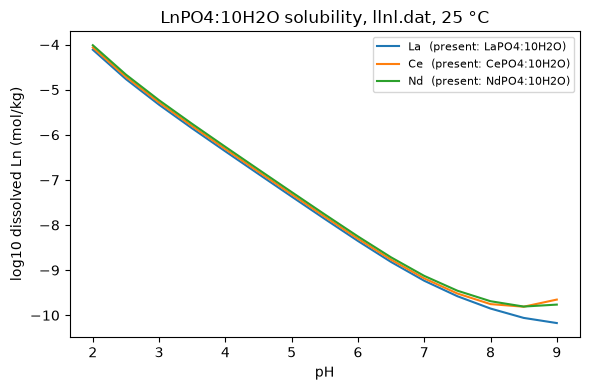

In [4]:
ln_pHs = np.arange(2.0, 9.01, 0.5)
fig, ax = plt.subplots(figsize=(6, 4))
for el in ["La", "Ce", "Nd"]:
    phos, hyd = f"{el}PO4:10H2O", f"{el}(OH)3(am)"
    print(f"{phos}: log K = {ll.phases[phos].logK:.4f}")
    s = ll.system([el, "P(5)", "Na", "Cl"], phases=[phos, hyd])
    tot, present = [], set()
    for pH in ln_pHs:
        r = s.equilibrate({phos: 1e-3, "Na": 0.01, "Cl": 0.01}, pH=pH, charge_balance="Cl-")
        assert r.converged
        tot.append(element_total(r, el)); present |= set(r.present)
    ax.plot(ln_pHs, np.log10(tot), label=f"{el}  (present: {', '.join(sorted(present))})")
ax.set(xlabel="pH", ylabel="log10 dissolved Ln (mol/kg)", title="LnPO4:10H2O solubility, llnl.dat, 25 °C")
ax.legend(fontsize=8); plt.tight_layout()

**Reading the plot.**
- **Phases present.** Only the phosphate, at every pH; `Ln(OH)3(am)` never forms up to pH 9.
- **Slope.** Dissolved Ln falls by about 1 log unit per pH unit from pH 2 to 7 (about 1e-4 to 1e-9 m), because the reaction consumes one H⁺.
- **Above pH 8.** The curves flatten; Ce and Nd level off while La keeps falling.

**Two warnings.**

**The constants look estimated.** The three `log K` values differ by exactly 0.1000. That pattern is typical of estimated, not measured, data. Differences between neighbouring lanthanides in these curves reflect aqueous complexation more than independent solubility measurements.

**The phases are not monazite.** These hydrated phosphates are like *rhabdophane*, the hydrated LnPO₄·nH₂O that precipitates from water at low temperature. They are not the anhydrous monazite of ore deposits, which is expected to be less soluble (section 5 shows how to add it).

## 3. Thorium in NaCl brines (sit.dat, SIT)

**Goal.** See how the activity model changes the Th⁴⁺ activity coefficient and ThO₂ solubility up to 3 m NaCl.

**Activity coefficients.** In the specific ion interaction theory, SIT (Guggenheim & Turgeon 1955, [doi:10.1039/TF9555100747](https://doi.org/10.1039/TF9555100747); NEA form in Grenthe et al. 1992), the activity coefficient of Th⁴⁺ ($z^2 = 16$) is
$\log_{10}\gamma = -16\,A\sqrt I/(1+1.5\sqrt I) + \sum_j \varepsilon(\mathrm{Th^{4+}}, j)\,m_j$.
The first term is Debye–Hückel; the sum runs over oppositely charged ions $j$, each with an *interaction coefficient* ε (kg/mol) fitted to experiments for that ion pair. [`sit.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/sit.dat) gives $\varepsilon(\mathrm{Th^{4+}},\mathrm{Cl^-}) = 0.25$ kg/mol. The Debye–Hückel term lowers log γ as I grows, but the ε term raises it linearly, so γ passes through a minimum.

**LLNL B-dot comparison.** B-dot (Helgeson 1969) adds one ḃ·I term that is the same for every ion; it has no ion-specific interaction term. It is shown here beyond its intended range (I ≲ 1 m).

**What the code does.** At each NaCl molality it computes γ(Th⁴⁺) with trace Th (1e-9 m) at pH 4 in both databases, then the solubility of ThO₂(fresh) at pH 5 and 6 with SIT.

SIT epsilon with Th+4: {('Th+4', 'Cl-'): 0.25, ('Th+4', 'ClO4-'): 0.7, ('Th+4', 'NO3-'): 0.31}


28 equilibria in 9.9 s


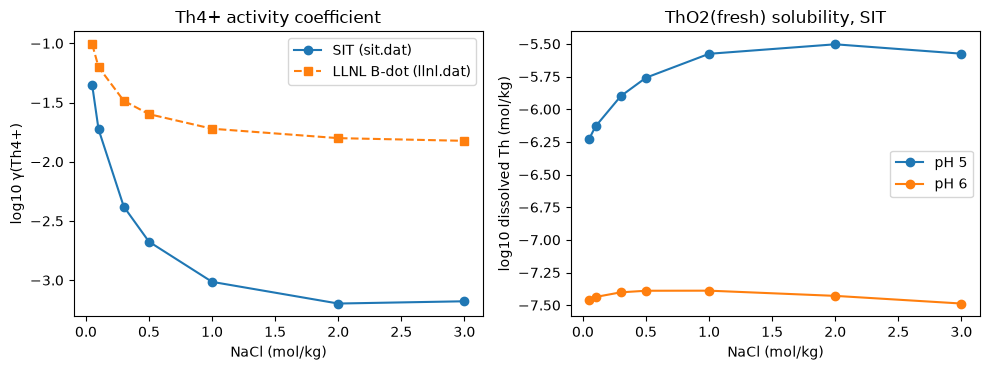

In [5]:
nacl = [0.05, 0.1, 0.3, 0.5, 1.0, 2.0, 3.0]
print("SIT epsilon with Th+4:", {k: v for k, v in si.sit.items() if "Th+4" in k})
sit_s = si.system(["Na", "Cl", "Th"], phases=["ThO2(fresh)"])
ll_s = ll.system(["Na", "Cl", "Th"])
g_sit, g_ll, sol = [], [], {5.0: [], 6.0: []}
t = time.time()
for m in nacl:
    r1 = sit_s.equilibrate({"Na": m, "Cl": m, "Th": 1e-9}, pH=4, charge_balance="Cl-")
    r2 = ll_s.equilibrate({"Na": m, "Cl": m, "Th": 1e-9}, pH=4, charge_balance="Cl-")
    g_sit.append(math.log10(r1.gamma["Th+4"]))
    g_ll.append(math.log10(r2.gamma["Th+4"]))
    for pH in sol:
        r = sit_s.equilibrate({"Na": m, "Cl": m, "ThO2(fresh)": 1e-2}, pH=pH, charge_balance="Cl-")
        assert r.converged and r.present == ["ThO2(fresh)"]
        sol[pH].append(math.log10(element_total(r, "Th")))
print(f"{4 * len(nacl)} equilibria in {time.time() - t:.1f} s")   # per NaCl value: 2 for gamma, 2 for solubility

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
axs[0].plot(nacl, g_sit, "o-", label="SIT (sit.dat)")
axs[0].plot(nacl, g_ll, "s--", label="LLNL B-dot (llnl.dat)")
axs[0].set(xlabel="NaCl (mol/kg)", ylabel="log10 γ(Th4+)", title="Th4+ activity coefficient"); axs[0].legend()
for pH, v in sol.items():
    axs[1].plot(nacl, v, "o-", label=f"pH {pH:g}")
axs[1].set(xlabel="NaCl (mol/kg)", ylabel="log10 dissolved Th (mol/kg)", title="ThO2(fresh) solubility, SIT"); axs[1].legend()
plt.tight_layout()

**Reading the plots.**
- **Where the models differ.** They differ already at 0.05 m, by about 0.35 log units, because B-dot uses the ion-size parameter å·B√I in the denominator while SIT uses a fixed 1.5√I. By 1 m they differ by more than a log unit. SIT γ reaches a shallow minimum near 2 m, where the ε term, fitted to Th data in chloride media, starts to win.
- **Why pH 5 depends on salt.** At pH 5, solubility is controlled by charged hydrolysis species. It rises by about 0.7 log units up to 1–2 m NaCl as their activity coefficients fall, then levels off.
- **Why pH 6 barely does.** At pH 6 the neutral Th(OH)₄(aq) dominates, and the curve hardly depends on NaCl.

**Choosing a model.** Above about 0.1 m NaCl the two models differ by up to 1.4 log units in γ(Th⁴⁺), and B-dot has no ion-specific data. For concentrated brines, such as those of radioactive waste repositories, use SIT with reviewed data ([`sit.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/sit.dat)); keep [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat) for dilute, high-temperature systems.

## 4. Temperature (llnl.dat)

**How temperature enters.** [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat) gives each reaction an analytic $\log K(T)$, and the B-dot parameters are tabulated from 0.01 to 300 °C. Calculations outside that table raise an error, as in PHREEQC.

**Caution.** Each species also has its own valid range (the `Range:` comments in the file), which PHREEQC and this package do not enforce.

**What is computed.** Thorianite solubility at pH 3 and LaPO₄·10H₂O solubility at pH 4, in 0.1 m NaCl from 25 to 300 °C. Temperature is passed to `equilibrate(..., T=...)` in kelvin. The cell ends with a deliberate call at 350 °C to show the out-of-range error.

350 °C: T = 350.00 C is outside the LLNL parameter range 0.01-300.0 C


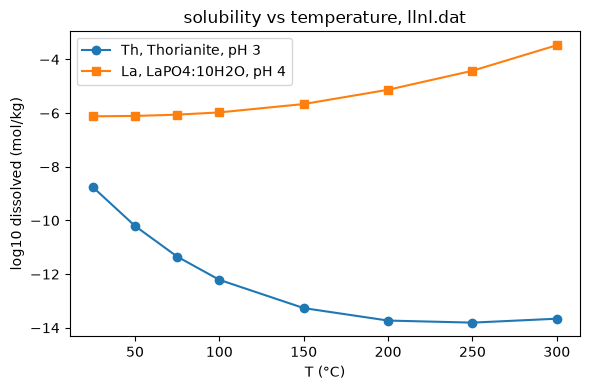

In [6]:
Tc = np.array([25, 50, 75, 100, 150, 200, 250, 300])
th_s = ll.system(["Na", "Cl", "Th"], phases=["Thorianite"])
la_s = ll.system(["La", "P(5)", "Na", "Cl"], phases=["LaPO4:10H2O"])
thT, laT = [], []
for T in Tc:
    r = th_s.equilibrate({"Na": 0.1, "Cl": 0.1, "Thorianite": 1e-2}, pH=3, charge_balance="Cl-", T=273.15 + T)
    q = la_s.equilibrate({"Na": 0.1, "Cl": 0.1, "LaPO4:10H2O": 1e-2}, pH=4, charge_balance="Cl-", T=273.15 + T)
    assert r.converged and q.converged
    thT.append(math.log10(element_total(r, "Th")))
    laT.append(math.log10(element_total(q, "La")))
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(Tc, thT, "o-", label="Th, Thorianite, pH 3")
ax.plot(Tc, laT, "s-", label="La, LaPO4:10H2O, pH 4")
ax.set(xlabel="T (°C)", ylabel="log10 dissolved (mol/kg)", title="solubility vs temperature, llnl.dat"); ax.legend()
plt.tight_layout()
try:
    th_s.equilibrate({"Na": 0.1, "Cl": 0.1, "Thorianite": 1e-2}, pH=3, charge_balance="Cl-", T=273.15 + 350)
except ValueError as e:
    print("350 °C:", e)

**Result.** The two solids go in opposite directions at fixed pH. *Retrograde* solubility decreases with temperature; *prograde* solubility increases.
- **Thorianite is retrograde.** Dissolved Th falls by about 5 log units from 25 to 200 °C, then levels off.
- **LaPO₄·10H₂O is prograde.** Dissolved La rises by about 2.6 log units, mostly above 100 °C.

Both trends come straight from the `-analytic` $\log K(T)$ expressions in [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat).

**Caveat on fixed pH.** A fixed pH hides the change of $K_w$ with temperature. In [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat), $\log K_w$ goes from −14.0 at 25 °C to −11.2 at 250 °C, so neutral pH drops to about 5.6. A fixed pH 3 is therefore *less* acidic relative to neutral at high temperature, and the trends partly reflect that.

## 5. Ore minerals not in the databases

Neither database contains the main REE and thorium ore minerals:

| mineral | formula | status |
|---------|---------|--------|
| monazite | (Ce,La,Nd,Th)PO₄ | not in either database; [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat) has only the hydrated LnPO₄·10H₂O |
| xenotime | YPO₄ | not in either database ([`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat) has Y³⁺ aqueous species) |
| bastnäsite | (Ce,La)CO₃F | not in either database |
| thorite / huttonite | ThSiO₄ | not in either database; no Th–silicate complexes |

**How to add one.** Declare the solid and its dissolution reaction, written with species already in the system, on a system built from the database. Complementarity then decides whether the new mineral replaces an existing phase.

**Monazite example.** The constant below, $\log K = -26.0$ for CePO₄ = Ce³⁺ + PO₄³⁻, is an **illustrative round number** of the magnitude reported for monazite. For real work, replace it with a critically evaluated value and its temperature dependence (`dH`, or `analytic`).

**What the code does.** It computes a baseline with only CePO₄·10H₂O, declares the new solid with `ce.solid(...)` and its reaction with `ce.reaction(...)`, then repeats the pH sweep with `rx.logK` set to −25, −26 and −27 to show the sensitivity to the uncertain constant.

log K -26, pH 5: present = ['CePO4(monazite)']  SI(CePO4:10H2O) = -1.38


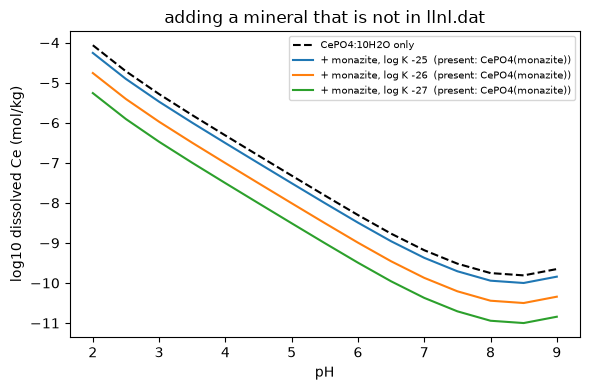

In [7]:
ce_pHs = np.arange(2.0, 9.01, 0.5)
ce = ll.system(["Ce(+3)", "P(5)", "Na", "Cl"], phases=["CePO4:10H2O"])
base = []
for pH in ce_pHs:
    r = ce.equilibrate({"CePO4:10H2O": 1e-3, "Na": 0.01, "Cl": 0.01}, pH=pH, charge_balance="Cl-")
    base.append(element_total(r, "Ce"))

mz = ce.solid("CePO4(monazite)")
rx = ce.reaction(mz >> ce["Ce+3"] + ce["PO4-3"], logK=-26.0, name="CePO4(monazite)")   # illustrative value
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ce_pHs, np.log10(base), "k--", label="CePO4:10H2O only")
for lk in [-25.0, -26.0, -27.0]:
    rx.logK = lk
    tot, present = [], set()
    for pH in ce_pHs:
        r = ce.equilibrate({"CePO4:10H2O": 1e-3, "Na": 0.01, "Cl": 0.01}, pH=pH, charge_balance="Cl-")
        assert r.converged
        tot.append(element_total(r, "Ce")); present |= set(r.present)
    ax.plot(ce_pHs, np.log10(tot), label=f"+ monazite, log K {lk:g}  (present: {', '.join(sorted(present))})")
ax.set(xlabel="pH", ylabel="log10 dissolved Ce (mol/kg)", title="adding a mineral that is not in llnl.dat")
ax.legend(fontsize=7); plt.tight_layout()
rx.logK = -26.0
r = ce.equilibrate({"CePO4:10H2O": 1e-3, "Na": 0.01, "Cl": 0.01}, pH=5.0, charge_balance="Cl-")
print("log K -26, pH 5: present =", r.present, " SI(CePO4:10H2O) =", round(r.SI["CePO4:10H2O"], 2))

**What happens.**
- The hydrated phosphate was given as the input solid. Monazite is more stable at all three log K values, so the Ce and P end up as monazite and the hydrated phase dissolves completely (SI = −1.38 at log K −26, pH 5).
- Dissolved Ce drops to the value set by monazite.
- **Sensitivity.** Each unit of $\log K$ moves dissolved Ce by about 0.5 log units. Ce and phosphate both come from the solid, so dissolved Ce scales roughly as $\sqrt{K}$.
- **At log K −25,** monazite is only slightly more stable than the hydrated phase (their $\log K$ values on the same basis are about −25 and −24.6), so the curves nearly coincide.

**If no reliable constant exists,** fit it to your own solubility data with confidence intervals, as in notebook 04. Use `fit.logK(system, "CePO4(monazite)")` as the parameter and dissolved Ce as the observation.

**Other ore minerals.** The same pattern adds the rest:
- xenotime: `YPO4 = Y+3 + PO4-3`;
- bastnäsite: `CeCO3F = Ce+3 + CO3-2 + F-`;
- thorite: `ThSiO4 + 4 H+ = Th+4 + SiO2 + 2 H2O`, using the `SiO2` aqueous species of [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat).

## Summary

- [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat) covers every lanthanide, Y and Th to 300 °C with LLNL B-dot; many constants are estimates, and it is meant for I ≲ 1 m.
- [`sit.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/sit.dat) (ThermoChimie) has reviewed Th data, several ThO₂ crystallinities and SIT for brines, mostly at 25 °C.
- Both reproduce PHREEQC to about 2e-4 in log activity.
- The crystallinity of the solid (≈ 7.5 log units for ThO₂) matters more than the database or activity model; use `suppress=` for metastable solubilities.
- Above about 0.1 m NaCl, SIT and B-dot differ strongly for Th⁴⁺; use SIT for brines.
- Ore minerals missing from both databases can be added with `system.solid` and `system.reaction`, and their log K fitted when no reliable value exists.

**Next steps.**
- Fit a constant such as the monazite log K: notebook 04 and [`docs/fitting.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/fitting.md).
- Diagrams for these systems: notebook 05 and [`docs/diagrams.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/diagrams.md).
- Model parameters and validity ranges: [`docs/activity-models.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/activity-models.md); overriding database values: [`docs/custom-data.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/custom-data.md).

## References

- Parkhurst, D.L., and Appelo, C.A.J. (2013). *Description of input and examples for PHREEQC version 3.* USGS Techniques and Methods 6-A43. [doi:10.3133/tm6A43](https://doi.org/10.3133/tm6A43)
- Delany, J.M., and Lundeen, S.R. (1991). *The LLNL thermochemical data base: revised data and file format for the EQ3/6 package.* LLNL UCID-21658. [OSTI 138193](https://www.osti.gov/biblio/138193) — [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat)
- Giffaut, E., et al. (2014). Andra thermodynamic database for performance assessment: ThermoChimie. *Applied Geochemistry* 49, 225–236. [doi:10.1016/j.apgeochem.2014.05.007](https://doi.org/10.1016/j.apgeochem.2014.05.007) — [`sit.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/sit.dat), v12a at [thermochimie-tdb.com](https://www.thermochimie-tdb.com)
- Helgeson, H.C. (1969). Thermodynamics of hydrothermal systems at elevated temperatures and pressures. *American Journal of Science* 267, 729–804. [doi:10.2475/ajs.267.7.729](https://doi.org/10.2475/ajs.267.7.729) — B-dot
- Drummond, S.E. (1981). *Boiling and mixing of hydrothermal fluids: chemical effects on mineral precipitation.* PhD thesis, Pennsylvania State University — CO₂(aq) activity coefficient in [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat)
- Scatchard, G. (1936). Concentrated solutions of strong electrolytes. *Chemical Reviews* 19, 309–327. [doi:10.1021/cr60064a008](https://doi.org/10.1021/cr60064a008) — SIT
- Guggenheim, E.A., and Turgeon, J.C. (1955). Specific interaction of ions. *Transactions of the Faraday Society* 51, 747. [doi:10.1039/TF9555100747](https://doi.org/10.1039/TF9555100747) — SIT
- Ciavatta, L. (1980). The specific interaction theory in evaluating ionic equilibria. *Annali di Chimica (Rome)* 70, 551–567 — SIT
- Grenthe, I., et al. (1992). *Chemical Thermodynamics of Uranium.* NEA-OECD, North-Holland. [NEA](https://www.oecd-nea.org/jcms/pl_13704) — the SIT form used by the NEA TDB and ThermoChimie

The full list is in [`docs/references.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/references.md).